# Klasifikasi Biner, Multikelas, dan Multilabel

Notebook ini membahas 3 jenis klasifikasi dengan masing-masing 3 dataset dari kaggle.com. Untuk setiap dataset, berikut adalah tahap pengolahan datanya: data diunduh, jenis klasifikasinya diidentifikasi dari bentuk targetnya, lalu beberapa model dilatih dan dievaluasi.

## Dataset yang digunakan

**Klasifikasi biner**
- (A1) Rice, Cammeo vs Osmancik (3.810 data; Target: Class): https://www.kaggle.com/datasets/muratkokludataset/rice-dataset-commeo-and-osmancik
- (A2) Online Shoppers Purchasing Intention (12.330 sesi; Target: Revenue (beli atau tidak)): https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset
- (A3) Pumpkin Seeds (2.500 biji; Target: Class (jenis biji labu)): https://www.kaggle.com/datasets/muratkokludataset/pumpkin-seeds-dataset

**Klasifikasi multikelas**
- (B1) Dry Bean (13.611 data; Target: Class (jenis kacang)): https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset
- (B2) Fetal Health (2.126 data; Target: fetal_health (kondisi janin)): https://www.kaggle.com/datasets/andrewmvd/fetal-health-classification
- (B3) Maternal Health Risk (1.014 data; Target: fetal_health (kondisi janin)): https://www.kaggle.com/datasets/csafrit2/maternal-health-risk-data

**Klasifikasi multilabel**
- (C1) PubMed MultiLabel Text Classification (sekitar 50 ribu artikel): https://www.kaggle.com/datasets/owaiskhan9654/pubmed-multilabel-text-classification
- (C2) MPST, sinopsis film dengan tag: https://www.kaggle.com/datasets/cryptexcode/mpst-movie-plot-synopses-with-tags
- (C3) GoEmotions, komentar Reddit dengan emosi: https://www.kaggle.com/datasets/debarshichanda/goemotions


## Cara mengidentifikasi jenis klasifikasi

- Biner: satu kolom target dengan tepat 2 nilai
- Multikelas: satu kolom target dengan lebih dari 2 nilai, dan tiap baris hanya punya satu kelas
- Multilabel: satu baris boleh punya lebih dari satu label sekaligus

## Metrik evaluasi

- Biner: precision, recall, F1, dan ROC-AUC. Pada data tidak seimbang, accuracy saja bisa menyesatkan
- Multikelas: accuracy, F1 macro, dan confusion matrix
- Multilabel: Hamming loss dan F1 (micro dan macro)

In [1]:
!pip -q install kagglehub openpyxl

In [2]:
import glob
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score,
                             accuracy_score, f1_score)

In [3]:
def baca_data(handle):
    # download dataset, baca file tabelnya
    folder = kagglehub.dataset_download(handle)
    semua = glob.glob(folder + "/**/*.*", recursive=True)
    print("Isi folder:", [f.split("/")[-1] for f in semua])
    for ext in (".csv", ".xlsx", ".xls", ".arff"):
        cocok = [f for f in semua if f.lower().endswith(ext)]
        if cocok:
            f = cocok[0]
            print("Dibaca:", f.split("/")[-1])
            if ext == ".csv":
                return pd.read_csv(f)
            if ext in (".xlsx", ".xls"):
                return pd.read_excel(f)
            data, _ = arff_io.loadarff(f)
            df = pd.DataFrame(data)
            for c in df.columns:
                if df[c].dtype == object:
                    df[c] = df[c].str.decode("utf-8")
            return df
    raise FileNotFoundError("Tidak ada file csv/xlsx/arff di folder ini")

# A. Klasifikasi Biner
Target hanya punya 2 kelas
## (A1) Rice (Cammeo vs Osmancik)

In [4]:
df = baca_data("muratkokludataset/rice-dataset-commeo-and-osmancik")
print(df.shape)
df.head()

100%|██████████| 524k/524k [00:00<00:00, 40.9MB/s]

Extracting files...
Isi folder: ['Rice_Dataset_(Commeo and Osmancik)_Citation_Request.txt', 'Rice_Cammeo_Osmancik.xlsx', 'Rice_Cammeo_Osmancik.arff', 'Rice Dataset (Commeo and Osmancik).docx']
Dibaca: Rice_Cammeo_Osmancik.xlsx


(3810, 8)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,15231,525.578979,229.749878,85.093788,0.928882,15617,0.572896,Cammeo
1,14656,494.311005,206.020065,91.730972,0.895405,15072,0.615436,Cammeo
2,14634,501.122009,214.106781,87.768288,0.912118,14954,0.693259,Cammeo
3,13176,458.342987,193.337387,87.448395,0.891861,13368,0.640669,Cammeo
4,14688,507.166992,211.743378,89.312454,0.906691,15262,0.646024,Cammeo


Class
Osmancik    2180
Cammeo      1630
Name: count, dtype: int64
Jumlah kelas: 2 -> biner


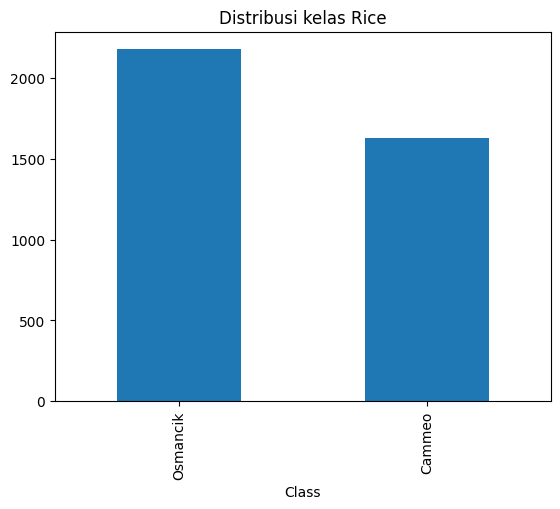

In [5]:
print(df["Class"].value_counts())
print("Jumlah kelas:", df["Class"].nunique(), "-> biner" if df["Class"].nunique() == 2 else "-> bukan biner")
df["Class"].value_counts().plot(kind="bar", title="Distribusi kelas Rice")
plt.show()

In [6]:
y, nama_kelas = pd.factorize(df["Class"])
print("0 =", nama_kelas[0], "| 1 =", nama_kelas[1])
X = df.drop(columns="Class")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

0 = Cammeo | 1 = Osmancik


In [7]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print("=====", nama, "| ROC-AUC:", round(auc, 3))
    print(classification_report(y_test, pred, target_names=nama_kelas))

===== Logistic Regression | ROC-AUC: 0.975
              precision    recall  f1-score   support

      Cammeo       0.92      0.88      0.90       326
    Osmancik       0.92      0.94      0.93       436

    accuracy                           0.92       762
   macro avg       0.92      0.91      0.91       762
weighted avg       0.92      0.92      0.92       762

===== KNN | ROC-AUC: 0.949
              precision    recall  f1-score   support

      Cammeo       0.91      0.88      0.89       326
    Osmancik       0.91      0.93      0.92       436

    accuracy                           0.91       762
   macro avg       0.91      0.91      0.91       762
weighted avg       0.91      0.91      0.91       762

===== Random Forest | ROC-AUC: 0.971
              precision    recall  f1-score   support

      Cammeo       0.93      0.87      0.90       326
    Osmancik       0.91      0.95      0.93       436

    accuracy                           0.91       762
   macro avg       0.

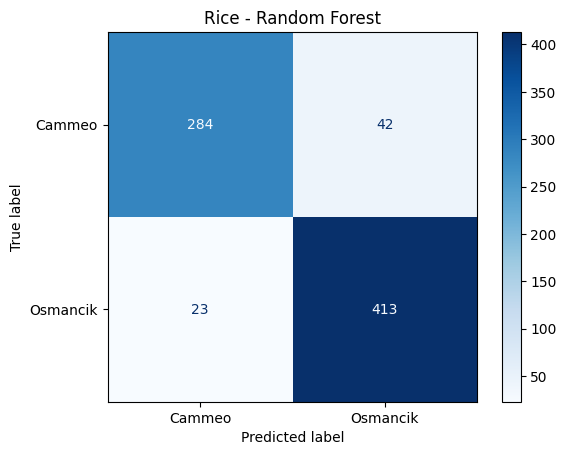

In [8]:
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=nama_kelas, cmap="Blues")
plt.title("Rice - Random Forest")
plt.show()

## (A2) Online Shoppers Purchasing Intention

In [9]:
df = baca_data("imakash3011/online-shoppers-purchasing-intention-dataset")
print(df.shape)
df.head()

100%|██████████| 252k/252k [00:00<00:00, 43.6MB/s]

Extracting files...
Isi folder: ['online_shoppers_intention.csv']
Dibaca: online_shoppers_intention.csv
(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    0.845
True     0.155
Name: proportion, dtype: float64


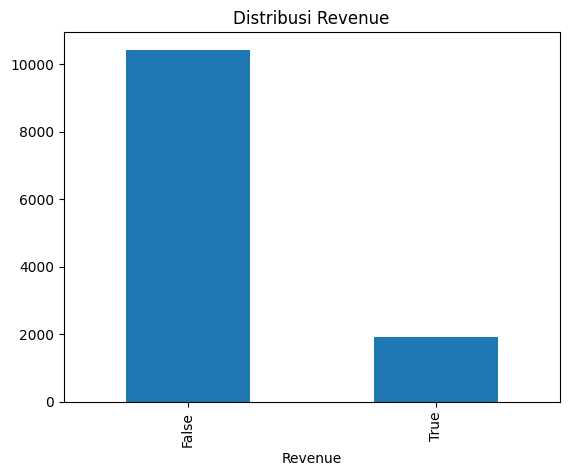

In [10]:
print(df["Revenue"].value_counts())
print(df["Revenue"].value_counts(normalize=True).round(3))
df["Revenue"].value_counts().plot(kind="bar", title="Distribusi Revenue")
plt.show()

In [11]:
y = df["Revenue"].astype(int)
X = pd.get_dummies(df.drop(columns="Revenue"), drop_first=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [12]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced")),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print("=====", nama, "| ROC-AUC:", round(auc, 3))
    print(classification_report(y_test, pred, target_names=["tidak beli", "beli"]))

===== Logistic Regression | ROC-AUC: 0.896
              precision    recall  f1-score   support

  tidak beli       0.95      0.87      0.91      2084
        beli       0.51      0.75      0.61       382

    accuracy                           0.85      2466
   macro avg       0.73      0.81      0.76      2466
weighted avg       0.88      0.85      0.86      2466

===== KNN | ROC-AUC: 0.772
              precision    recall  f1-score   support

  tidak beli       0.89      0.96      0.93      2084
        beli       0.64      0.35      0.45       382

    accuracy                           0.87      2466
   macro avg       0.76      0.66      0.69      2466
weighted avg       0.85      0.87      0.85      2466

===== Random Forest | ROC-AUC: 0.919
              precision    recall  f1-score   support

  tidak beli       0.91      0.97      0.94      2084
        beli       0.74      0.51      0.60       382

    accuracy                           0.90      2466
   macro avg       0.

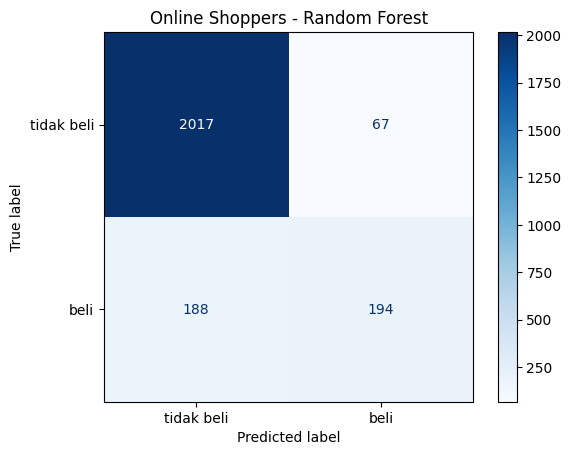

In [13]:
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=["tidak beli", "beli"], cmap="Blues")
plt.title("Online Shoppers - Random Forest")
plt.show()

## (A3) Pumpkin Seeds (Urgup Sivrisi vs Cercevelik)

In [14]:
df = baca_data("muratkokludataset/pumpkin-seeds-dataset")
print(df.shape)
df.head()

100%|██████████| 393k/393k [00:00<00:00, 35.0MB/s]

Extracting files...
Isi folder: ['Pumpkin_Seeds_Dataset.arff', 'Pumpkin_Seeds_Dataset.xlsx', 'Pumpkin_Seeds_Dataset_Citation_Request.txt']
Dibaca: Pumpkin_Seeds_Dataset.xlsx


(2500, 13)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Convex_Area,Equiv_Diameter,Eccentricity,Solidity,Extent,Roundness,Aspect_Ration,Compactness,Class
0,56276,888.242,326.1485,220.2388,56831,267.6805,0.7376,0.9902,0.7453,0.8963,1.4809,0.8207,Çerçevelik
1,76631,1068.146,417.1932,234.2289,77280,312.3614,0.8275,0.9916,0.7151,0.8440,1.7811,0.7487,Çerçevelik
2,71623,1082.987,435.8328,211.0457,72663,301.9822,0.8749,0.9857,0.7400,0.7674,2.0651,0.6929,Çerçevelik
3,66458,992.051,381.5638,222.5322,67118,290.8899,0.8123,0.9902,0.7396,0.8486,1.7146,0.7624,Çerçevelik
4,66107,998.146,383.8883,220.4545,67117,290.1207,0.8187,0.9850,0.6752,0.8338,1.7413,0.7557,Çerçevelik


Class
Çerçevelik       1300
Ürgüp Sivrisi    1200
Name: count, dtype: int64
Jumlah kelas: 2 -> biner


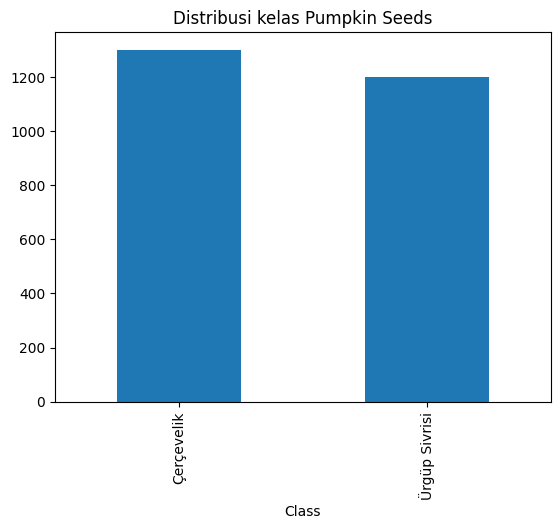

In [15]:
print(df["Class"].value_counts())
print("Jumlah kelas:", df["Class"].nunique(), "-> biner" if df["Class"].nunique() == 2 else "-> bukan biner")
df["Class"].value_counts().plot(kind="bar", title="Distribusi kelas Pumpkin Seeds")
plt.show()

In [16]:
y, nama_kelas = pd.factorize(df["Class"])
print("0 =", nama_kelas[0], "| 1 =", nama_kelas[1])
X = df.drop(columns="Class")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

0 = Çerçevelik | 1 = Ürgüp Sivrisi


In [17]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print("=====", nama, "| ROC-AUC:", round(auc, 3))
    print(classification_report(y_test, pred, target_names=nama_kelas))

===== Logistic Regression | ROC-AUC: 0.934
               precision    recall  f1-score   support

   Çerçevelik       0.85      0.90      0.87       260
Ürgüp Sivrisi       0.88      0.82      0.85       240

     accuracy                           0.86       500
    macro avg       0.86      0.86      0.86       500
 weighted avg       0.86      0.86      0.86       500

===== KNN | ROC-AUC: 0.911
               precision    recall  f1-score   support

   Çerçevelik       0.83      0.91      0.87       260
Ürgüp Sivrisi       0.89      0.80      0.84       240

     accuracy                           0.86       500
    macro avg       0.86      0.86      0.86       500
 weighted avg       0.86      0.86      0.86       500

===== Random Forest | ROC-AUC: 0.94
               precision    recall  f1-score   support

   Çerçevelik       0.86      0.90      0.88       260
Ürgüp Sivrisi       0.89      0.84      0.87       240

     accuracy                           0.87       500
    ma

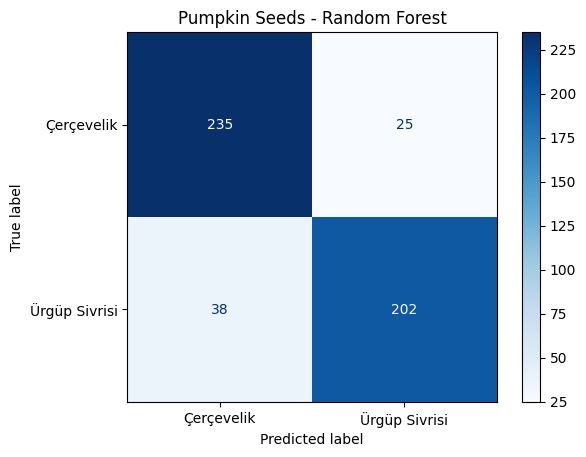

In [18]:
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=nama_kelas, cmap="Blues")
plt.title("Pumpkin Seeds - Random Forest")
plt.show()

# B. Klasifikasi Multikelas
Target berupa satu kolom dengan lebih dari 2 kelas, dan tiap baris hanya punya satu kelas. Selain accuracy, dilihat juga F1 macro (rata-rata F1 tiap kelas, sehingga kelas kecil ikut dihitung) dan confusion matrix untuk melihat kelas mana yang sering tertukar.
## (B1) Dry Bean

In [19]:
df = baca_data("muratkokludataset/dry-bean-dataset")
print(df.shape)
df.head()

Using Colab cache for faster access to the 'dry-bean-dataset' dataset.
Isi folder: ['Dry_Bean_Dataset_Citation_Request.txt', 'Dry_Bean_Dataset.xlsx', 'Dry_Bean_Dataset.arff']
Dibaca: Dry_Bean_Dataset.xlsx
(13611, 17)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64
Jumlah kelas: 7 -> multikelas


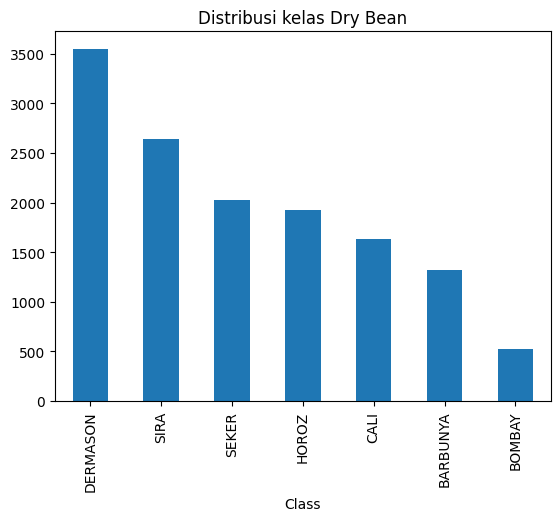

In [20]:
print(df["Class"].value_counts())
print("Jumlah kelas:", df["Class"].nunique(), "-> multikelas" if df["Class"].nunique() > 2 else "-> bukan multikelas")
df["Class"].value_counts().plot(kind="bar", title="Distribusi kelas Dry Bean")
plt.show()

In [21]:
y, nama_kelas = pd.factorize(df["Class"])
X = df.drop(columns="Class")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [22]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("=====", nama)
    print("Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("F1 macro :", round(f1_score(y_test, pred, average="macro"), 3))

print()
print(classification_report(y_test, models["Random Forest"].predict(X_test), target_names=nama_kelas))

===== Logistic Regression
Accuracy : 0.922
F1 macro : 0.932
===== KNN
Accuracy : 0.93
F1 macro : 0.941
===== Random Forest
Accuracy : 0.927
F1 macro : 0.937

              precision    recall  f1-score   support

       SEKER       0.94      0.94      0.94       406
    BARBUNYA       0.94      0.91      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.93      0.93       326
       HOROZ       0.96      0.95      0.95       386
        SIRA       0.89      0.87      0.88       527
    DERMASON       0.91      0.94      0.93       709

    accuracy                           0.93      2723
   macro avg       0.94      0.93      0.94      2723
weighted avg       0.93      0.93      0.93      2723



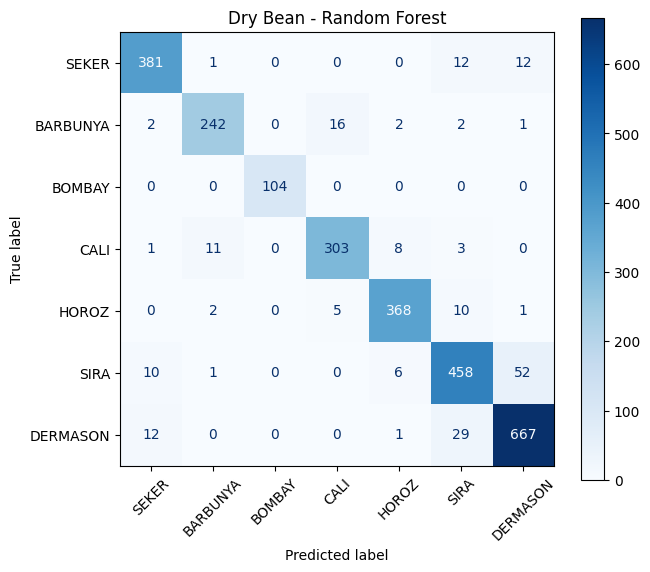

In [23]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=nama_kelas, cmap="Blues",
                                      xticks_rotation=45, ax=ax)
plt.title("Dry Bean - Random Forest")
plt.show()

## (B2) Fetal Health Classification

In [24]:
df = baca_data("andrewmvd/fetal-health-classification")
print(df.shape)
df.head()

Using Colab cache for faster access to the 'fetal-health-classification' dataset.
Isi folder: ['fetal_health.csv']
Dibaca: fetal_health.csv
(2126, 22)


,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


fetal_health
Normal          1655
Suspect          295
Pathological     176
Name: count, dtype: int64
fetal_health
Normal          0.778
Suspect         0.139
Pathological    0.083
Name: proportion, dtype: float64
Jumlah kelas: 3 -> multikelas


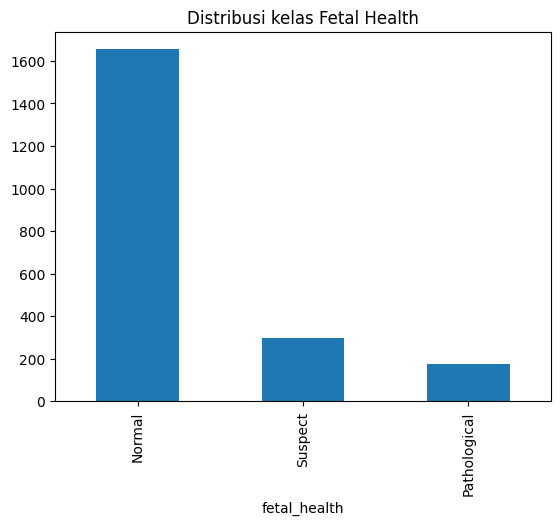

In [25]:
# 1 = Normal, 2 = Suspect, 3 = Pathological
nama_kondisi = {1: "Normal", 2: "Suspect", 3: "Pathological"}
kelas = df["fetal_health"].astype(int).map(nama_kondisi)

print(kelas.value_counts())
print(kelas.value_counts(normalize=True).round(3))
print("Jumlah kelas:", kelas.nunique(), "-> multikelas" if kelas.nunique() > 2 else "-> bukan multikelas")
kelas.value_counts().plot(kind="bar", title="Distribusi kelas Fetal Health")
plt.show()

In [26]:
y, nama_kelas = pd.factorize(kelas, sort=True)
X = df.drop(columns="fetal_health")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [27]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("=====", nama)
    print("Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("F1 macro :", round(f1_score(y_test, pred, average="macro"), 3))

print()
print(classification_report(y_test, models["Random Forest"].predict(X_test), target_names=nama_kelas))

===== Logistic Regression
Accuracy : 0.864
F1 macro : 0.787
===== KNN
Accuracy : 0.901
F1 macro : 0.814
===== Random Forest
Accuracy : 0.948
F1 macro : 0.912

              precision    recall  f1-score   support

      Normal       0.96      0.98      0.97       332
Pathological       0.94      0.97      0.96        35
     Suspect       0.88      0.75      0.81        59

    accuracy                           0.95       426
   macro avg       0.93      0.90      0.91       426
weighted avg       0.95      0.95      0.95       426



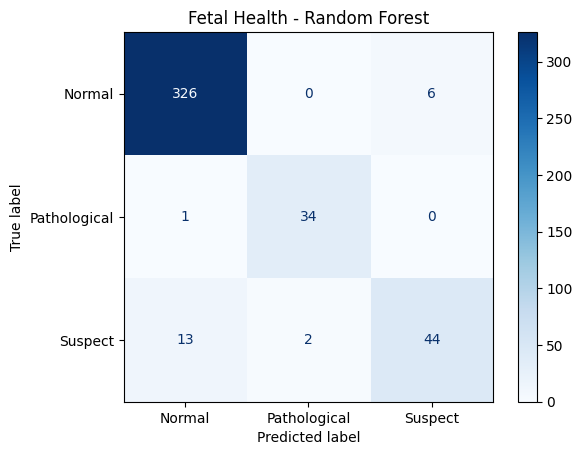

In [28]:
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=nama_kelas, cmap="Blues")
plt.title("Fetal Health - Random Forest")
plt.show()

## (B3) Maternal Health Risk

In [29]:
df = baca_data("csafrit2/maternal-health-risk-data")
print(df.shape)
df.head()

100%|██████████| 3.77k/3.77k [00:00<00:00, 2.69MB/s]

Extracting files...
Isi folder: ['Maternal Health Risk Data Set.csv']
Dibaca: Maternal Health Risk Data Set.csv
(1014, 7)


,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


RiskLevel
low risk     406
mid risk     336
high risk    272
Name: count, dtype: int64
Jumlah kelas: 3 -> multikelas


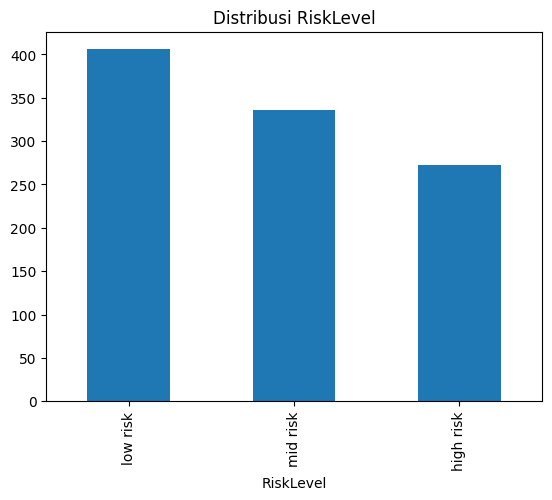

In [30]:
print(df["RiskLevel"].value_counts())
print("Jumlah kelas:", df["RiskLevel"].nunique(), "-> multikelas" if df["RiskLevel"].nunique() > 2 else "-> bukan multikelas")
df["RiskLevel"].value_counts().plot(kind="bar", title="Distribusi RiskLevel")
plt.show()

In [31]:
y, nama_kelas = pd.factorize(df["RiskLevel"], sort=True)
X = df.drop(columns="RiskLevel")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

In [32]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print("=====", nama)
    print("Accuracy :", round(accuracy_score(y_test, pred), 3))
    print("F1 macro :", round(f1_score(y_test, pred, average="macro"), 3))

print()
print(classification_report(y_test, models["Random Forest"].predict(X_test), target_names=nama_kelas))

===== Logistic Regression
Accuracy : 0.621
F1 macro : 0.61
===== KNN
Accuracy : 0.67
F1 macro : 0.679
===== Random Forest
Accuracy : 0.862
F1 macro : 0.87

              precision    recall  f1-score   support

   high risk       0.96      0.95      0.95        55
    low risk       0.90      0.80      0.85        81
    mid risk       0.75      0.87      0.81        67

    accuracy                           0.86       203
   macro avg       0.87      0.87      0.87       203
weighted avg       0.87      0.86      0.86       203



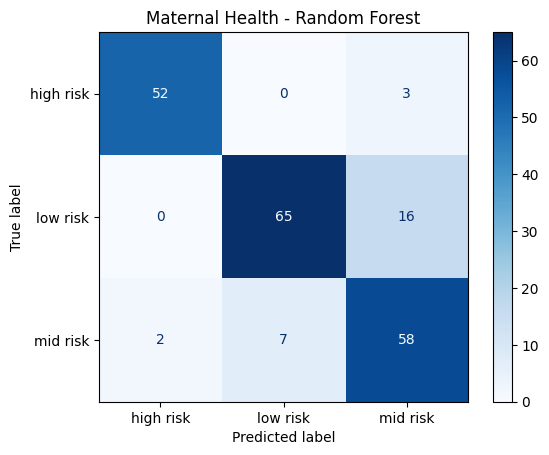

In [33]:
ConfusionMatrixDisplay.from_estimator(models["Random Forest"], X_test, y_test,
                                      display_labels=nama_kelas, cmap="Blues")
plt.title("Maternal Health - Random Forest")
plt.show()

In [34]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import hamming_loss

# C. Klasifikasi Multilabel
Satu baris bisa memiliki beberapa label sekaligus, sehingga target diubah menjadi tabel 0/1. Multilabel dibuktikan dengan metrik hamming loss (proporsi label yang salah, makin kecil makin baik), subset accuracy (semua label dalam satu baris harus benar), serta F1 micro dan macro. Ketiga dataset berupa teks, sehingga fitur dibuat dengan metode TF-IDF.

## (C1) PubMed MultiLabel Text Classification

In [35]:
df = baca_data("owaiskhan9654/pubmed-multilabel-text-classification")
print(df.shape)
print(list(df.columns))
df.head(3)

100%|██████████| 45.1M/45.1M [00:00<00:00, 176MB/s]

Extracting files...


Isi folder: ['PubMed Multi Label Text Classification Dataset.csv', 'PubMed Multi Label Text Classification Dataset Processed.csv']
Dibaca: PubMed Multi Label Text Classification Dataset.csv
(10000, 22)
['Title', 'abstractText', 'meshMajor', 'pmid', 'meshid', 'meshroot', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'V', 'Z']


,Title,abstractText,meshMajor,pmid,meshid,meshroot,A,B,C,D,...,G,H,I,J,K,L,M,N,V,Z
0,Expression of p53 and coexistence of HPV in pr...,Fifty-four paraffin embedded tissue sections f...,"['DNA Probes, HPV', 'DNA, Viral', 'Female', 'H...",8549602,"[['D13.444.600.223.555', 'D27.505.259.750.600....","['Chemicals and Drugs [D]', 'Organisms [B]', '...",0,1,1,1,...,0,1,0,0,0,0,0,0,0,0
1,Vitamin D status in pregnant Indian women acro...,The present cross-sectional study was conducte...,"['Adult', 'Alkaline Phosphatase', 'Breast Feed...",21736816,"[['M01.060.116'], ['D08.811.277.352.650.035'],...","['Named Groups [M]', 'Chemicals and Drugs [D]'...",0,1,1,1,...,1,0,1,1,0,0,1,1,0,1
2,[Identification of a functionally important di...,The occurrence of individual amino acids and d...,"['Amino Acid Sequence', 'Analgesics, Opioid', ...",19060934,"[['G02.111.570.060', 'L01.453.245.667.060'], [...","['Phenomena and Processes [G]', 'Information S...",1,1,0,1,...,1,0,0,0,0,1,0,0,0,0


Kolom label: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'L', 'M', 'N', 'Z']
Jumlah artikel di data: 10000
Jumlah label          : 14
Label cardinality     : 5.707
Baris dengan >1 label : 99.2 %
=> Multilabel


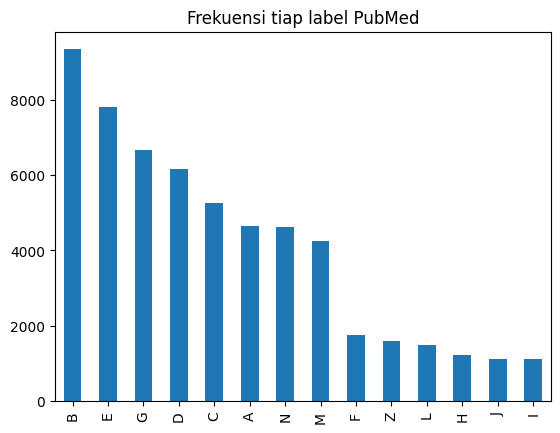

In [38]:
kolom_label = [c for c in list("ABCDEFGHIJLMNZ") if c in df.columns]
kolom_teks = [c for c in ["Title", "abstractText"] if c in df.columns]
print("Kolom label:", kolom_label)
print("Jumlah artikel di data:", len(df))

# ambil sample maksimal 20.000 artikel
jumlah = min(20000, len(df))
df = df.sample(jumlah, random_state=42).reset_index(drop=True)
teks = df[kolom_teks].fillna("").agg(" ".join, axis=1)
Y = df[kolom_label].astype(int)

per_baris = Y.sum(axis=1)
print("Jumlah label          :", Y.shape[1])
print("Label cardinality     :", round(per_baris.mean(), 3))
print("Baris dengan >1 label :", round((per_baris > 1).mean() * 100, 1), "%")
print("=> Multilabel" if (per_baris > 1).any() else "=> Bukan multilabel")
Y.sum().sort_values(ascending=False).plot(kind="bar", title="Frekuensi tiap label PubMed")
plt.show()

In [39]:
X_train, X_test, Y_train, Y_test = train_test_split(teks, Y, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, stop_words="english")
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

models = {
    "OvR Logistic Regression": OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "OvR Linear SVM": OneVsRestClassifier(LinearSVC(class_weight="balanced")),
}

for nama, model in models.items():
    model.fit(Xtr, Y_train)
    pred = model.predict(Xte)
    print("=====", nama)
    print("Hamming loss    :", round(hamming_loss(Y_test, pred), 3))
    print("Subset accuracy :", round(accuracy_score(Y_test, pred), 3))
    print("F1 micro        :", round(f1_score(Y_test, pred, average="micro", zero_division=0), 3))
    print("F1 macro        :", round(f1_score(Y_test, pred, average="macro", zero_division=0), 3))

===== OvR Logistic Regression
Hamming loss    : 0.151
Subset accuracy : 0.113
F1 micro        : 0.815
F1 macro        : 0.745
===== OvR Linear SVM
Hamming loss    : 0.148
Subset accuracy : 0.12
F1 micro        : 0.818
F1 macro        : 0.733


## (C2) MPST: Movie Plot Synopses with Tags
Karena satu film punya banyak tag, diambil dengan sample 20 tag yang paling sering muncul.

In [40]:
df = baca_data("cryptexcode/mpst-movie-plot-synopses-with-tags")
print(df.shape)
print(list(df.columns))
df.head(3)

100%|██████████| 28.8M/28.8M [00:00<00:00, 183MB/s]

Extracting files...


Isi folder: ['mpst_full_data.csv', 'partition.json']
Dibaca: mpst_full_data.csv
(14828, 6)
['imdb_id', 'title', 'plot_synopsis', 'tags', 'split', 'synopsis_source']


,imdb_id,title,plot_synopsis,tags,split,synopsis_source
0,tt0057603,I tre volti della paura,Note: this synopsis is for the orginal Italian...,"cult, horror, gothic, murder, atmospheric",train,imdb
1,tt1733125,Dungeons & Dragons: The Book of Vile Darkness,"Two thousand years ago, Nhagruul the Foul, a s...",violence,train,imdb
2,tt0033045,The Shop Around the Corner,"Matuschek's, a gift store in Budapest, is the ...",romantic,test,imdb


Total tag unik: 71
Jumlah label          : 20
Label cardinality     : 2.271
Baris dengan >1 label : 53.5 %
=> Multilabel


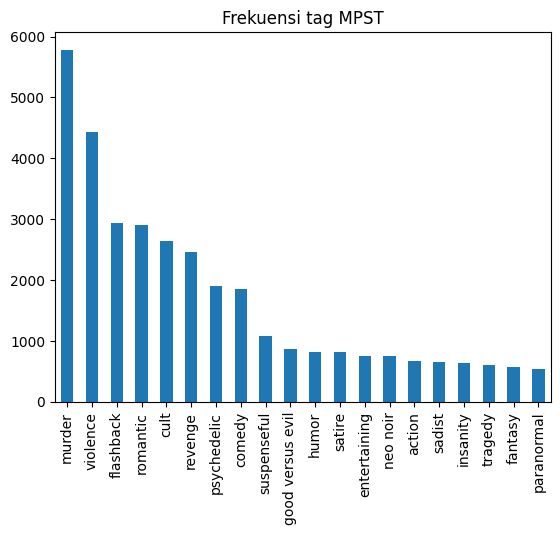

In [41]:
# kolom "tags" berisi beberapa tag dipisah koma
daftar_tag = df["tags"].fillna("").apply(lambda s: [t.strip() for t in s.split(",") if t.strip()])

mlb = MultiLabelBinarizer()
Y_semua = pd.DataFrame(mlb.fit_transform(daftar_tag), columns=mlb.classes_)
print("Total tag unik:", Y_semua.shape[1])

top20 = Y_semua.sum().sort_values(ascending=False).head(20).index
Y = Y_semua[top20]
teks = df["plot_synopsis"].fillna("")

per_baris = Y.sum(axis=1)
print("Jumlah label          :", Y.shape[1])
print("Label cardinality     :", round(per_baris.mean(), 3))
print("Baris dengan >1 label :", round((per_baris > 1).mean() * 100, 1), "%")
print("=> Multilabel" if (per_baris > 1).any() else "=> Bukan multilabel")
Y.sum().sort_values(ascending=False).plot(kind="bar", title="Frekuensi tag MPST")
plt.show()

In [42]:
X_train, X_test, Y_train, Y_test = train_test_split(teks, Y, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=3, stop_words="english")
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

models = {
    "OvR Logistic Regression": OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "OvR Linear SVM": OneVsRestClassifier(LinearSVC(class_weight="balanced")),
}

for nama, model in models.items():
    model.fit(Xtr, Y_train)
    pred = model.predict(Xte)
    print("=====", nama)
    print("Hamming loss    :", round(hamming_loss(Y_test, pred), 3))
    print("Subset accuracy :", round(accuracy_score(Y_test, pred), 3))
    print("F1 micro        :", round(f1_score(Y_test, pred, average="micro", zero_division=0), 3))
    print("F1 macro        :", round(f1_score(Y_test, pred, average="macro", zero_division=0), 3))

===== OvR Logistic Regression
Hamming loss    : 0.167
Subset accuracy : 0.058
F1 micro        : 0.423
F1 macro        : 0.336
===== OvR Linear SVM
Hamming loss    : 0.149
Subset accuracy : 0.067
F1 micro        : 0.402
F1 macro        : 0.304


## (C3) GoEmotions
Satu komentar Reddit bisa punya beberapa emosi sekaligus.

In [44]:
folder = kagglehub.dataset_download("debarshichanda/goemotions")

semua = glob.glob(folder + "/**/*.*", recursive=True)
print("Isi folder:")
for f in semua:
    print(" -", f)

berkas = [f for f in semua if f.endswith("train.tsv")]
df = pd.read_csv(berkas[0], sep="\t", header=None, names=["text", "labels", "id"])
print(df.shape)
df.head(3)

Using Colab cache for faster access to the 'goemotions' dataset.
Isi folder:
 - /kaggle/input/goemotions/README.md
 - /kaggle/input/goemotions/goemotions_model_card.pdf
 - /kaggle/input/goemotions/GoEmotionsFormat.PNG
 - /kaggle/input/goemotions/replace_emotions.py
 - /kaggle/input/goemotions/extract_words.py
 - /kaggle/input/goemotions/calculate_metrics.py
 - /kaggle/input/goemotions/analyze_data.py
 - /kaggle/input/goemotions/tables/emotion_words.csv
 - /kaggle/input/goemotions/data/test.tsv
 - /kaggle/input/goemotions/data/ekman_mapping.json
 - /kaggle/input/goemotions/data/dev.tsv
 - /kaggle/input/goemotions/data/emotions.txt
 - /kaggle/input/goemotions/data/train.tsv
 - /kaggle/input/goemotions/data/ekman_labels.csv
 - /kaggle/input/goemotions/data/sentiment_dict.json
 - /kaggle/input/goemotions/data/sentiment_mapping.json
 - /kaggle/input/goemotions/data/full_dataset/goemotions_2.csv
 - /kaggle/input/goemotions/data/full_dataset/goemotions_1.csv
 - /kaggle/input/goemotions/data/f

,text,labels,id
0,My favourite food is anything I didn't have to...,27,eebbqej
1,"Now if he does off himself, everyone will thin...",27,ed00q6i
2,WHY THE FUCK IS BAYLESS ISOING,2,eezlygj


Jumlah label          : 28
Label cardinality     : 1.177
Baris dengan >1 label : 16.4 %
=> Multilabel


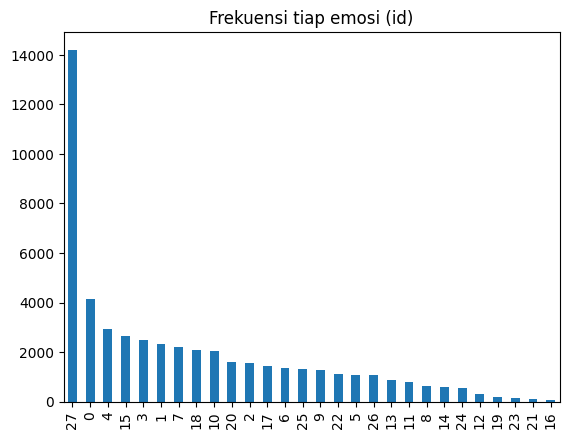

In [45]:
daftar = df["labels"].astype(str).apply(lambda s: [int(x) for x in s.split(",")])
mlb = MultiLabelBinarizer()
Y = pd.DataFrame(mlb.fit_transform(daftar), columns=mlb.classes_)
teks = df["text"].fillna("")

per_baris = Y.sum(axis=1)
print("Jumlah label          :", Y.shape[1])
print("Label cardinality     :", round(per_baris.mean(), 3))
print("Baris dengan >1 label :", round((per_baris > 1).mean() * 100, 1), "%")
print("=> Multilabel" if (per_baris > 1).any() else "=> Bukan multilabel")
Y.sum().sort_values(ascending=False).plot(kind="bar", title="Frekuensi tiap emosi (id)")
plt.show()

In [46]:
X_train, X_test, Y_train, Y_test = train_test_split(teks, Y, test_size=0.2, random_state=42)

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)

models = {
    "OvR Logistic Regression": OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "OvR Linear SVM": OneVsRestClassifier(LinearSVC(class_weight="balanced")),
}

for nama, model in models.items():
    model.fit(Xtr, Y_train)
    pred = model.predict(Xte)
    print("=====", nama)
    print("Hamming loss    :", round(hamming_loss(Y_test, pred), 3))
    print("Subset accuracy :", round(accuracy_score(Y_test, pred), 3))
    print("F1 micro        :", round(f1_score(Y_test, pred, average="micro", zero_division=0), 3))
    print("F1 macro        :", round(f1_score(Y_test, pred, average="macro", zero_division=0), 3))

===== OvR Logistic Regression
Hamming loss    : 0.058
Subset accuracy : 0.216
F1 micro        : 0.491
F1 macro        : 0.426
===== OvR Linear SVM
Hamming loss    : 0.049
Subset accuracy : 0.264
F1 micro        : 0.481
F1 macro        : 0.39
